# 02 — User-Based Collaborative Filtering

**Ide dasar:** user yang seleranya mirip di masa lalu kemungkinan juga mirip di masa depan. Untuk menebak
rating user **a** pada film **i**, kita cari user lain yang mirip dengan a dan sudah menonton film i,
lalu lihat bagaimana mereka menilainya.

Langkah-langkah (sesuai slide M02):
1. Hitung kemiripan antar-user dengan **Pearson correlation**.
2. Pilih **k tetangga** paling mirip yang sudah merating film i.
3. Hitung prediksi dari rata-rata user a ditambah rata-rata tertimbang "selisih rating" para tetangga.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
RES = ROOT / "results"; RES.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import plot_style as ps
ps.setup()
pd.set_option("display.precision", 4)
from src.data import load_fold, load_ratings, load_items, to_matrix, unique_titles
from src.metrics import evaluate
from src.ubcf import UserBasedCF, pearson_similarity

## Langkah 0 — Memastikan kode benar dengan contoh Alice di slide

Sebelum dipakai ke data besar, kode diuji dengan contoh di slide M02. Hasil yang diharapkan:
sim(Alice, User1) = 0,85; sim(Alice, User2) = 0,70; sim(Alice, User3) = 0,00; sim(Alice, User4) = −0,79,
dan prediksi Alice untuk Item5 = **4,87**.

In [2]:
nan = np.nan
alice = np.array([[5, 3, 4, 4, nan],
                  [3, 1, 2, 3, 3],
                  [4, 3, 4, 3, 5],
                  [3, 3, 1, 5, 4],
                  [1, 5, 5, 2, 1]])
nama = ["Alice", "User1", "User2", "User3", "User4"]
sim, _ = pearson_similarity(alice)
print(pd.Series(sim[0, 1:], index=nama[1:], name="sim(Alice, .)").round(2))

model_alice = UserBasedCF(k=2).fit(alice)
print("\nPrediksi Alice untuk Item5 =", round(model_alice.predict(0, 4), 2))

User1    0.85
User2    0.71
User3    0.00
User4   -0.79
Name: sim(Alice, .), dtype: float64

Prediksi Alice untuk Item5 = 4.87


### Rumus Pearson correlation

$$sim(a,b) = \frac{\sum_{p \in P} (r_{a,p} - \bar{r}_a)(r_{b,p} - \bar{r}_b)}
{\sqrt{\sum_{p \in P} (r_{a,p} - \bar{r}_a)^2}\ \sqrt{\sum_{p \in P} (r_{b,p} - \bar{r}_b)^2}}$$

- $P$ = film yang dirating **kedua** user (co-rated)
- $r_{a,p}$ = rating user a untuk film p, $\bar{r}_a$ = rata-rata rating user a
- Nilainya antara −1 (selera berlawanan) sampai 1 (selera sangat mirip)

Di kode, rumus ini ditulis dalam bentuk perkalian matriks agar kemiripan **semua pasangan** dari 943 user
dihitung sekaligus, bukan satu per satu dengan perulangan.

## Langkah 1 — Menyiapkan data fold 1 menjadi matriks rating

Baris = user, kolom = film. Sel tanpa rating diisi `NaN` (bukan 0), karena 0 bukan rating, melainkan
"belum menonton".

In [3]:
train, test = load_fold(1)
R = to_matrix(train)
print("Ukuran matriks R:", R.shape)
print("Sel terisi      :", int((~np.isnan(R)).sum()))
print("Data uji        :", len(test), "rating yang disembunyikan")
pd.DataFrame(R[:5, :8], index=[f"user {u}" for u in range(1, 6)], columns=[f"film {i}" for i in range(1, 9)])

Ukuran matriks R: (943, 1682)
Sel terisi      : 80000
Data uji        : 20000 rating yang disembunyikan


,film 1,film 2,film 3,film 4,film 5,film 6,film 7,film 8
user 1,5.0,3.0,4.0,3.0,3.0,NaN,4.0,1.0
user 2,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user 3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user 4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user 5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Langkah 2 — Menghitung kemiripan antar-user

Satu masalah muncul di data asli: dua user yang kebetulan hanya punya **2–3 film yang sama** bisa
mendapat korelasi sempurna (1,0), padahal buktinya sangat sedikit. Slide M02 menyebut perbaikannya,
yaitu **significance weighting**: kemiripan dikurangi secara linear jika jumlah film co-rated sedikit.

$$sim'(a,b) = sim(a,b) \times \frac{\min(n_{ab},\ 50)}{50}$$

dengan $n_{ab}$ = jumlah film co-rated. Pasangan dengan ≥ 50 film sama tidak dikurangi sama sekali.

In [4]:
model = UserBasedCF(k=30, sig_weight=50).fit(R)

u = 0  # user 1 (indeks 0)
tetangga = pd.DataFrame({
    "user": np.arange(1, R.shape[0] + 1),
    "pearson_asli": pearson_similarity(R)[0][u],
    "film_co_rated": model.n_common[u].astype(int),
    "sim_setelah_bobot": model.sim[u],
}).drop(index=u)
print("5 user paling mirip dengan user 1 SEBELUM significance weighting:")
display(tetangga.sort_values("pearson_asli", ascending=False).head(5))
print("5 user paling mirip dengan user 1 SESUDAH significance weighting:")
display(tetangga.sort_values("sim_setelah_bobot", ascending=False).head(5))

5 user paling mirip dengan user 1 SEBELUM significance weighting:


,user,pearson_asli,film_co_rated,sim_setelah_bobot
28,29,1.0,3,0.06
897,898,1.0,2,0.04
45,46,1.0,3,0.06
8,9,1.0,2,0.04
925,926,1.0,3,0.06


5 user paling mirip dengan user 1 SESUDAH significance weighting:


,user,pearson_asli,film_co_rated,sim_setelah_bobot
879,880,0.5770,67,0.5770
891,892,0.5505,49,0.5395
591,592,0.5159,69,0.5159
649,650,0.4979,64,0.4979
885,886,0.4865,56,0.4865


## Langkah 3 — Membuat satu prediksi secara rinci

$$pred(a,i) = \bar{r}_a + \frac{\sum_{b \in N} sim(a,b)\,(r_{b,i} - \bar{r}_b)}{\sum_{b \in N} sim(a,b)}$$

- $N$ = k tetangga paling mirip (similarity positif) yang sudah merating film i
- $(r_{b,i} - \bar{r}_b)$ = apakah tetangga b menilai film i **lebih tinggi atau lebih rendah** dari kebiasaannya
- Selisih ini dirata-rata dengan bobot kemiripan, lalu ditambahkan ke rata-rata user a

Mengapa memakai selisih, bukan rating mentah? Ada user yang "pelit" (rata-rata 2,5) dan ada yang
"murah hati" (rata-rata 4,5). Rating 4 dari user pelit artinya sangat suka, sedangkan dari user murah hati
artinya biasa saja. Selisih terhadap rata-rata menghilangkan perbedaan kebiasaan ini.

In [5]:
contoh = test[test["user"] == 1].iloc[0]
a, i = contoh["user"] - 1, contoh["item"] - 1
cand, s = model.neighbors(a, i)
rinci = pd.DataFrame({
    "tetangga": cand + 1,
    "sim": s,
    "rating_film": R[cand, i],
    "rata2_tetangga": model.user_mean[cand],
}).sort_values("sim", ascending=False)
rinci["selisih"] = rinci["rating_film"] - rinci["rata2_tetangga"]
rinci["sim_x_selisih"] = rinci["sim"] * rinci["selisih"]
display(rinci.head(10))

pembilang, penyebut = rinci["sim_x_selisih"].sum(), rinci["sim"].sum()
print(f"Prediksi user {a+1} untuk film {i+1}:")
print(f"  rata-rata user {a+1}        = {model.user_mean[a]:.4f}")
print(f"  sum(sim x selisih)       = {pembilang:.4f}")
print(f"  sum(sim)                 = {penyebut:.4f}")
print(f"  pred = {model.user_mean[a]:.4f} + {pembilang:.4f} / {penyebut:.4f} = {model.user_mean[a] + pembilang / penyebut:.4f}")
print(f"  rating asli              = {contoh['rating']}")

,tetangga,sim,rating_film,rata2_tetangga,selisih,sim_x_selisih
11,773,0.4355,3.0,3.2795,-0.2795,-0.1217
10,758,0.3559,2.0,3.8768,-1.8768,-0.6679
12,806,0.2521,2.0,3.6429,-1.6429,-0.4141
8,655,0.2466,4.0,2.9080,1.0920,0.2693
14,870,0.2399,4.0,3.4535,0.5465,0.1311
3,198,0.1819,2.0,3.2547,-1.2547,-0.2283
4,486,0.1729,4.0,3.2222,0.7778,0.1345
13,828,0.1420,1.0,3.1154,-2.1154,-0.3004
9,707,0.1204,3.0,3.4958,-0.4958,-0.0597
16,936,0.1018,5.0,3.7465,1.2535,0.1276


Prediksi user 1 untuk film 6:
  rata-rata user 1        = 3.6815
  sum(sim x selisih)       = -1.1976
  sum(sim)                 = 2.5325
  pred = 3.6815 + -1.1976 / 2.5325 = 3.2086
  rating asli              = 5


## Langkah 4 — Prediksi seluruh data uji fold 1 dan evaluasi

Kelima metrik dihitung sesuai slide. Untuk NDCG@10, film-film milik setiap user di data uji diurutkan
berdasarkan prediksi, lalu film dianggap **relevan jika rating aslinya ≥ 4** (aturan Kuis 2).

In [6]:
pred = model.predict_df(test)
display(pred.head(8))
hasil_fold1 = pd.Series(evaluate(pred)).to_frame("UBCF fold 1")
hasil_fold1

,user,item,rating,timestamp,pred
0,1,6,5,887431973,3.2086
1,1,10,3,875693118,3.8649
2,1,12,5,878542960,4.8293
3,1,14,5,874965706,3.8565
4,1,17,3,875073198,3.3598
5,1,20,4,887431883,3.6668
6,1,23,4,875072895,4.4207
7,1,24,3,875071713,3.7440


,UBCF fold 1
MAE,0.7416
MSE,0.9094
RMSE,0.9536
NMSE,0.2273
NDCG@10,0.8446


## Analisis sensitivitas: jumlah tetangga k dan significance weighting

Slide M02 menyebutkan bahwa k terlalu kecil membuat prediksi kurang akurat, sedangkan k terlalu besar
memasukkan "noise" dari tetangga yang tidak terlalu mirip, dan kisaran 20–50 dianggap wajar. Kami
menetapkan **k = 30** dan **significance weighting (γ = 50)** sejak awal berdasarkan slide; tabel di bawah
hanya untuk melihat seberapa sensitif hasilnya, bukan untuk memilih k terbaik berdasarkan data uji.

In [7]:
rows = []
for sw, label in [(None, "Pearson biasa"), (50, "Dengan significance weighting")]:
    m = UserBasedCF(sig_weight=sw).fit(R)
    for k in [10, 20, 30, 50, 100]:
        m.k = k
        rows.append({"Varian": label, "k": k, **evaluate(m.predict_df(test))})
sens = pd.DataFrame(rows)
sens.to_csv(RES / "ubcf_sensitivitas_k.csv", index=False)
sens.pivot(index="k", columns="Varian", values=["MAE", "RMSE", "NDCG@10"]).round(4)

MAE                \
Varian Dengan significance weighting Pearson biasa   
k                                                    
10                            0.7492        0.7761   
20                            0.7419        0.7592   
30                            0.7416        0.7552   
50                            0.7424        0.7525   
100                           0.7454        0.7525   

                                RMSE                \
Varian Dengan significance weighting Pearson biasa   
k                                                    
10                            0.9659        0.9917   
20                            0.9554        0.9708   
30                            0.9536        0.9653   
50                            0.9533        0.9619   
100                           0.9551        0.9619   

                             NDCG@10                
Varian Dengan significance weighting Pearson biasa  
k                                                   
10                            0.8380        0.8089  
20                            0.8470        0.8247  
30                            0.8446        0.8336  
50                            0.8463        0.8344  
100                           0.8465        0.8402

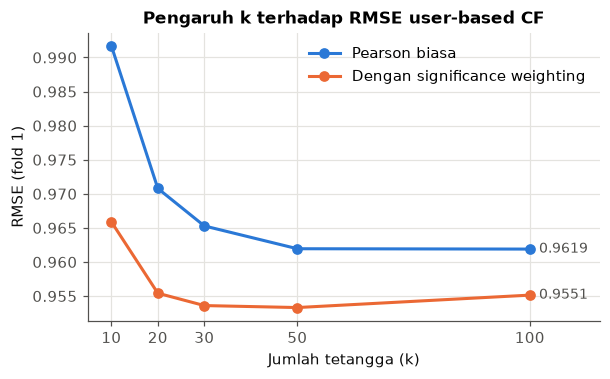

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.4))
for (label, g), color in zip(sens.groupby("Varian", sort=False), [ps.BLUE, ps.ORANGE]):
    ax.plot(g["k"], g["RMSE"], marker="o", color=color, label=label)
    ax.annotate(f"{g['RMSE'].iloc[-1]:.4f}", (g["k"].iloc[-1], g["RMSE"].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=ps.INK_2)
ax.set_xlabel("Jumlah tetangga (k)")
ax.set_ylabel("RMSE (fold 1)")
ax.set_title("Pengaruh k terhadap RMSE user-based CF")
ax.set_xticks([10, 20, 30, 50, 100])
ax.set_xlim(5, 115)
ax.legend(loc="upper right")
fig.savefig(FIG / "ubcf_sensitivitas_k.png")
plt.show()

## Langkah 5 — Evaluasi di kelima fold

Agar hasil tidak bergantung pada satu pembagian data saja (pedoman di slide Evaluasi Part 1), model dilatih
ulang di setiap fold, lalu nilai metrik dirata-rata.

In [9]:
rows = []
for k in range(1, 6):
    tr, te = load_fold(k)
    m = UserBasedCF(k=30, sig_weight=50).fit(to_matrix(tr))
    rows.append({"Fold": k, **evaluate(m.predict_df(te))})
ubcf_5fold = pd.DataFrame(rows).set_index("Fold")
ubcf_5fold.loc["Rata-rata"] = ubcf_5fold.mean()
ubcf_5fold.loc["Simpangan baku"] = ubcf_5fold.iloc[:5].std()
ubcf_5fold.to_csv(RES / "ubcf_5fold.csv")
ubcf_5fold.round(4)

,MAE,MSE,RMSE,NMSE,NDCG@10
Fold,,,,,
1,0.7416,0.9094,0.9536,0.2273,0.8446
2,0.7317,0.8909,0.9439,0.2227,0.8379
3,0.7324,0.8859,0.9412,0.2215,0.8413
4,0.7296,0.8808,0.9385,0.2202,0.8547
5,0.7357,0.8835,0.9399,0.2209,0.8584
Rata-rata,0.7342,0.8901,0.9434,0.2225,0.8474
Simpangan baku,0.0047,0.0114,0.0060,0.0029,0.0088


## Langkah 6 — Rekomendasi film untuk satu user

Untuk rekomendasi sungguhan, model dilatih memakai **seluruh** 100.000 rating. Lalu untuk user 1, semua film
yang belum ia tonton diprediksi ratingnya, dan 10 film dengan prediksi tertinggi direkomendasikan.

Jika semua film boleh masuk, peringkat teratas langsung dikuasai film obscure dengan prediksi 5,0 yang
hanya didukung 1–2 tetangga (lihat tabel pertama). Prediksi seperti itu buktinya terlalu lemah, sehingga
untuk rekomendasi kami mensyaratkan film dirating minimal **5 tetangga** (tabel kedua).

In [10]:
titles = load_items()
full = UserBasedCF(k=30, sig_weight=50).fit(to_matrix(load_ratings()))

def tabel_rek(rek):
    return pd.DataFrame([{"Peringkat": r + 1, "Film": titles[i + 1], "Prediksi rating": round(p, 3), "Jumlah tetangga": n}
                         for r, (i, p, n) in enumerate(rek)]).set_index("Peringkat")

print("Tanpa syarat jumlah tetangga:")
display(tabel_rek(unique_titles(full.recommend(0, n=40, min_neighbors=1), titles, np.flatnonzero(full.rated[0]))))
print("Dengan syarat minimal 5 tetangga:")
rek = unique_titles(full.recommend(0, n=40, min_neighbors=5), titles, np.flatnonzero(full.rated[0]))
tabel_rek(rek)

Tanpa syarat jumlah tetangga:


,Film,Prediksi rating,Jumlah tetangga
Peringkat,,,
1,Two or Three Things I Know About Her (1966),5.000,3
2,"Saint of Fort Washington, The (1993)",5.000,2
3,Santa with Muscles (1996),5.000,2
4,"Great Day in Harlem, A (1994)",5.000,1
5,Aiqing wansui (1994),5.000,1
6,Someone Else's America (1995),5.000,1
7,Some Mother's Son (1996),4.915,2
8,Hearts and Minds (1996),4.864,4
9,Pather Panchali (1955),4.834,8


Dengan syarat minimal 5 tetangga:


,Film,Prediksi rating,Jumlah tetangga
Peringkat,,,
1,Pather Panchali (1955),4.834,8
2,"Close Shave, A (1995)",4.759,30
3,Casablanca (1942),4.729,30
4,Faust (1994),4.678,5
5,Schindler's List (1993),4.643,30
6,L.A. Confidential (1997),4.617,30
7,Secrets & Lies (1996),4.592,30
8,Rear Window (1954),4.557,30
9,Dr. Strangelove or: How I Learned to Stop Worr...,4.541,30


## Kesimpulan user-based CF

- Kode sudah diverifikasi dengan contoh Alice di slide (prediksi 4,87).
- Pearson tanpa koreksi cenderung tertipu oleh pasangan user dengan sangat sedikit film co-rated;
  significance weighting memperbaiki MAE dan RMSE di semua nilai k.
- Hasil cukup stabil untuk k = 20–50, sesuai saran slide.
- Nilai rata-rata 5-fold dipakai untuk perbandingan dengan item-based CF dan matrix factorization.